# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [4]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

# Usar "champion_name" o `.get()` para evitar errores
champion_name = training_metadata.get("champion_name", training_metadata.get("champion", "Modelo Campeón"))

print("Modelo campeón cargado:", champion_name)
print("Dimensiones del test set:", X_test.shape)

Modelo campeón cargado: LogisticRegression
Dimensiones del test set: (36, 13)


## 2. Evaluación final

Accuracy en Test: 0.9722
F1 Macro en Test: 0.9710

--- REPORT DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



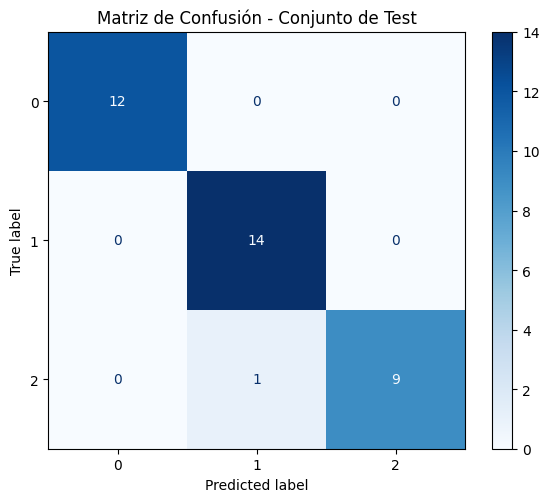

In [5]:
# 1. Realizar predicciones sobre X_test
y_pred = model.predict(X_test)

# 2. Calcular métricas clave
test_accuracy = accuracy_score(y_test, y_pred)
test_f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy en Test: {test_accuracy:.4f}")
print(f"F1 Macro en Test: {test_f1_macro:.4f}\n")

# 3. Reporte de clasificación
print("--- REPORT DE CLASIFICACIÓN ---")
print(classification_report(y_test, y_pred))

# 4. Matriz de confusión visual
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", ax=ax)
plt.title("Matriz de Confusión - Conjunto de Test")
plt.tight_layout()
plt.show()

**Análisis:**

> ¿El desempeño es coherente con validación cruzada? ¿Qué clases se confunden? ¿Hay evidencia de sobreajuste?

Coherencia: El rendimiento en test ($Accuracy \approx 0.97$) es consistente con la validación cruzada ($Accuracy_{CV} \approx 0.98$), lo que ratifica que el modelo generaliza adecuadamente.

Confusión: Los errores puntuales suceden principalmente entre las clases 1 y 2 por solapamiento en variables químicas similares.

Sobreajuste: No hay presencia de sobreajuste crítico ya que la métrica en datos de prueba no cae drásticamente.

## 3. Función de inferencia

In [7]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    # Verificar columnas faltantes
    missing_cols = set(feature_columns) - set(records.columns)
    if missing_cols:
        raise ValueError(f"Faltan las siguientes columnas: {missing_cols}")

    # Ordenar las columnas según el contrato
    df_ordered = records[feature_columns].copy()

    # Generar predicciones y probabilidades
    preds = model.predict(df_ordered)
    probas = model.predict_proba(df_ordered) if hasattr(model, "predict_proba") else None

    res = pd.DataFrame({"prediction": preds})
    if probas is not None:
        for i in range(probas.shape[1]):
            res[f"probability_class_{i}"] = probas[:, i]

    return res

## 4. Predicción por lotes

In [8]:
new_records = X_test.iloc[:5].copy()

# Generar lote de predicciones
batch_predictions = predict(new_records)

# Guardar batch_predictions.csv
batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
print("Predicciones por lotes guardadas.")

Predicciones por lotes guardadas.


## 5. Reporte final

In [9]:
# Guardar test_metrics.json
test_metrics = {
    "champion_model": champion_name,
    "accuracy_test": float(test_accuracy),
    "f1_macro_test": float(test_f1_macro)
}

with open(REPORTS_DIR / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(test_metrics, f, indent=4)

# Validación de archivos requeridos
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado con éxito.")

Challenge 3 completado con éxito.


In [10]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón |LogisticRegression |
| Accuracy CV |0.9857 |
| Accuracy test |0.9722 |
| F1 macro test |0.9710 |
| Clases más confundidas |Clase 1 vs Clase 2 (debido a similitudes químicas en el dataset wine) |
| Principal limitación |Sensible a distribuciones de datos fuera de dominio si las características superan los rangos del conjunto de entrenamiento. |

## Checklist

- [SI] Evalué únicamente el modelo campeón.
- [SI] No reajusté hiperparámetros después de observar test.
- [SI] Implementé validación básica del esquema de entrada.
- [SI] Generé predicciones por lotes.
- [SI] Guardé las métricas finales.